# 3 — Inspeção do estado oculto e das portas da GRU

Este notebook abre um modelo treinado no notebook 2 e mostra, para um evento escolhido:

- estado oculto (h_t);
- porta de atualização (z_t);
- porta de reinicialização (r_t);
- estado candidato (n_t);
- sensibilidade da saída a cada dia da janela.

**Atenção conceitual:** uma GRU não possui a “porta de entrada” (i_t) da LSTM. A entrada (x_t) influencia (r_t), (z_t) e (n_t). Por isso, além das portas próprias da GRU, o notebook calcula o gradiente da previsão em relação a cada total diário de entrada.

In [8]:
# Se faltar alguma biblioteca, descomente e execute uma vez:
# %pip install torch pandas numpy matplotlib seaborn ipywidgets

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import torch
    from torch import nn
    import torch.nn.functional as F
except ImportError as e:
    raise ImportError("PyTorch não está instalado. Execute a linha de instalação acima.") from e

from IPython.display import display, clear_output
sns.set_theme(style="whitegrid")

## Configuração

In [9]:
PASTA_MODELOS = Path("modelos")
CAMINHO_DADOS = Path("dados_processados/chuva_horaria_padronizada.csv")

# None seleciona automaticamente o modelo .pt mais recente.
MODELO_ESCOLHIDO = None

# None seleciona o maior total diário do teste. Também pode usar "2022-05-12".
DATA_EVENTO = "2024-05-12"

# None mostra a camada GRU superior. Para duas camadas, também pode usar 0 ou 1.
CAMADA_PARA_GRAFICO = None

## Reconstrução do modelo e das amostras

In [10]:
class GRUDesagregadora(nn.Module):
    def __init__(self, hidden_size, n_outputs, num_layers=1):
        super().__init__()
        self.gru = nn.GRU(
            1, hidden_size, num_layers=num_layers, batch_first=True,
            dropout=0.0 if num_layers == 1 else 0.1,
        )
        self.fc = nn.Linear(hidden_size, n_outputs)

    def forward(self, x, total_central):
        sequencia, h_n = self.gru(x)
        logits = self.fc(sequencia[:, -1, :])
        fracoes = torch.softmax(logits, dim=1)
        return fracoes * total_central[:, None], fracoes, h_n


def carregar_checkpoint(caminho):
    caminho = Path(caminho)
    try:
        ckpt = torch.load(caminho, map_location="cpu", weights_only=False)
    except TypeError:  # compatibilidade com versões antigas do PyTorch
        ckpt = torch.load(caminho, map_location="cpu")
    cfg = ckpt["config"]
    modelo = GRUDesagregadora(cfg["hidden_size"], cfg["n_outputs"], cfg["num_layers"])
    modelo.load_state_dict(ckpt["state_dict"])
    modelo.eval()
    return modelo, cfg


def carregar_horario(caminho):
    df = pd.read_csv(caminho, parse_dates=["data_hora"])
    df["precipitacao_mm"] = pd.to_numeric(df["precipitacao_mm"], errors="coerce")
    return df.sort_values("data_hora").set_index("data_hora")


def construir_amostras_teste(horario, cfg):
    janela_dias = cfg["janela_dias"]
    intervalo = cfg["intervalo_horas"]
    metade = janela_dias // 2
    grupos = horario["precipitacao_mm"].groupby(horario.index.normalize())
    arrays = {}
    for data, serie in grupos:
        serie = serie.sort_index()
        if len(serie) == 24 and serie.notna().all():
            arrays[pd.Timestamp(data)] = serie.to_numpy(np.float32)
    totais = {d: float(v.sum()) for d, v in arrays.items()}
    datas_ok = set(arrays)
    corte_val = pd.Timestamp(cfg["fim_validacao"])

    amostras = []
    for central in sorted(arrays):
        janela = [central + pd.Timedelta(days=i) for i in range(-metade, metade + 1)]
        if not all(d in datas_ok for d in janela):
            continue
        if janela[0] <= corte_val or totais[central] < cfg["limiar_chuva_mm"]:
            continue
        x_raw = np.array([totais[d] for d in janela], dtype=np.float32)[:, None]
        x_norm = (np.log1p(x_raw) - cfg["media_log_treino"]) / cfg["desvio_log_treino"]
        y = arrays[central].reshape(-1, intervalo).sum(axis=1).astype(np.float32)
        amostras.append({
            "data": central, "datas_janela": janela,
            "x_raw": x_raw, "x_norm": x_norm.astype(np.float32),
            "y": y, "total": totais[central],
        })
    if not amostras:
        raise ValueError("Não foi possível reconstruir amostras de teste.")
    return amostras

## Equações internas da GRU do PyTorch

In [11]:
def calcular_portas_manualmente(modelo, x):
    # Reproduz a GRU em modo de avaliação e retorna portas por camada e passo.
    if x.ndim != 3 or x.shape[0] != 1:
        raise ValueError("Use uma única sequência com forma [1, tempo, 1].")
    gru = modelo.gru
    batch, passos, _ = x.shape
    estados = [torch.zeros(batch, gru.hidden_size, dtype=x.dtype) for _ in range(gru.num_layers)]
    registros = [dict(r=[], z=[], n=[], h=[]) for _ in range(gru.num_layers)]

    for t in range(passos):
        entrada_camada = x[:, t, :]
        novos_estados = []
        for camada in range(gru.num_layers):
            W_ih = getattr(gru, f"weight_ih_l{camada}")
            W_hh = getattr(gru, f"weight_hh_l{camada}")
            b_ih = getattr(gru, f"bias_ih_l{camada}")
            b_hh = getattr(gru, f"bias_hh_l{camada}")
            h_anterior = estados[camada]

            gi = F.linear(entrada_camada, W_ih, b_ih)
            gh = F.linear(h_anterior, W_hh, b_hh)
            i_r, i_z, i_n = gi.chunk(3, dim=1)  # ordem do PyTorch: r, z, n
            h_r, h_z, h_n = gh.chunk(3, dim=1)

            r = torch.sigmoid(i_r + h_r)
            z = torch.sigmoid(i_z + h_z)
            n = torch.tanh(i_n + r * h_n)
            h = (1.0 - z) * n + z * h_anterior

            for nome, valor in [("r", r), ("z", z), ("n", n), ("h", h)]:
                registros[camada][nome].append(valor.detach().cpu().numpy()[0])
            novos_estados.append(h)
            entrada_camada = h  # entrada da próxima camada
        estados = novos_estados

    for camada in registros:
        for nome in camada:
            camada[nome] = np.stack(camada[nome])
    h_final = torch.stack(estados, dim=0)
    return registros, h_final


def verificar_equacoes(modelo, x, total):
    with torch.no_grad():
        pred_torch, _, h_torch = modelo(x, total)
        registros, h_manual = calcular_portas_manualmente(modelo, x)
        h_superior = h_manual[-1]
        frac_manual = torch.softmax(modelo.fc(h_superior), dim=1)
        pred_manual = frac_manual * total[:, None]
    erro_h = float(torch.max(torch.abs(h_torch - h_manual)))
    erro_pred = float(torch.max(torch.abs(pred_torch - pred_manual)))
    print(f"Diferença máxima no estado oculto: {erro_h:.3e}")
    print(f"Diferença máxima na previsão:     {erro_pred:.3e}")
    if erro_h > 1e-5 or erro_pred > 1e-5:
        warnings.warn("As equações manuais não coincidiram dentro da tolerância esperada.")
    return registros, pred_torch.numpy()[0]

## Inspeção visual de um evento

In [12]:
def selecionar_modelo(modelo_escolhido=None):
    if modelo_escolhido is not None:
        caminho = Path(modelo_escolhido)
        if not caminho.exists():
            caminho = PASTA_MODELOS / modelo_escolhido
        return caminho
    candidatos = sorted(PASTA_MODELOS.glob("*.pt"), key=lambda p: p.stat().st_mtime)
    if not candidatos:
        raise FileNotFoundError("Nenhum modelo .pt encontrado. Execute primeiro o notebook 2.")
    return candidatos[-1]


def escolher_amostra(amostras, data_evento=None):
    if data_evento is None:
        return max(amostras, key=lambda a: a["total"])
    alvo = pd.Timestamp(data_evento).normalize()
    encontrados = [a for a in amostras if a["data"].normalize() == alvo]
    if not encontrados:
        disponiveis = [str(a["data"].date()) for a in sorted(amostras, key=lambda a: a["total"], reverse=True)[:10]]
        raise KeyError(f"Data não disponível no teste. Dez maiores eventos: {disponiveis}")
    return encontrados[0]


def inspecionar_evento(caminho_modelo=None, data_evento=None, camada=None):
    caminho = selecionar_modelo(caminho_modelo)
    modelo, cfg = carregar_checkpoint(caminho)
    horario = carregar_horario(CAMINHO_DADOS)
    amostras = construir_amostras_teste(horario, cfg)
    amostra = escolher_amostra(amostras, data_evento)
    camada = cfg["num_layers"] - 1 if camada is None else int(camada)
    if camada < 0 or camada >= cfg["num_layers"]:
        raise ValueError(f"Camada deve estar entre 0 e {cfg['num_layers'] - 1}.")

    x = torch.tensor(amostra["x_norm"][None, :, :], dtype=torch.float32)
    total = torch.tensor([amostra["total"]], dtype=torch.float32)
    registros, pred = verificar_equacoes(modelo, x, total)
    reg = registros[camada]
    obs = amostra["y"]
    rotulos_dias = [str(pd.Timestamp(d).date()) for d in amostra["datas_janela"]]

    print("Modelo:", caminho.name)
    print("Configuração:", cfg)
    print(f"Evento: {amostra['data'].date()} | total={amostra['total']:.2f} mm")
    display(pd.DataFrame({
        "data_janela": rotulos_dias,
        "precipitacao_diaria_mm": amostra["x_raw"].ravel(),
        "entrada_normalizada": amostra["x_norm"].ravel(),
    }))

    # 1) Observado versus previsto
    n = cfg["n_outputs"]
    intervalo = cfg["intervalo_horas"]
    blocos = np.arange(n) * intervalo
    fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
    largura = 0.38 * intervalo
    ax.bar(blocos - largura/2, obs, width=largura, label="observado", color="#2474B5")
    ax.bar(blocos + largura/2, pred, width=largura, label="GRU", color="#E69F00")
    ax.set(xlabel="Início do intervalo (h)", ylabel=f"mm/{intervalo}h", title=f"Evento {amostra['data'].date()}")
    ax.legend(); plt.show()

    # 2) Estado oculto e portas
    fig, axes = plt.subplots(4, 1, figsize=(14, 13), constrained_layout=True)
    mapas = [("h", "Estado oculto h", "vlag", -1, 1),
             ("z", "Porta de atualização z", "viridis", 0, 1),
             ("r", "Porta de reinicialização r", "viridis", 0, 1),
             ("n", "Estado candidato n", "vlag", -1, 1)]
    for ax, (chave, titulo, cmap, vmin, vmax) in zip(axes, mapas):
        sns.heatmap(reg[chave], ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
                    xticklabels=5 if cfg["hidden_size"] > 32 else True,
                    yticklabels=rotulos_dias, cbar_kws={"label": "ativação"})
        ax.set(title=f"{titulo} — camada {camada}", xlabel="Unidade oculta", ylabel="Dia da janela")
    plt.show()

    # 3) Resumo médio das portas por passo temporal
    resumo = pd.DataFrame({
        "data": pd.to_datetime(amostra["datas_janela"]),
        "z_media": reg["z"].mean(axis=1),
        "r_media": reg["r"].mean(axis=1),
        "n_media": reg["n"].mean(axis=1),
        "h_media": reg["h"].mean(axis=1),
    })
    display(resumo)
    ax = resumo.set_index("data")[["z_media", "r_media"]].plot(marker="o", figsize=(11, 4))
    ax.set(ylabel="Ativação média", title="Comportamento médio das portas", ylim=(0, 1))
    plt.show()

    # 4) Sensibilidade: gradiente do pico previsto em relação à entrada
    x_grad = x.clone().detach().requires_grad_(True)
    pred_grad, _, _ = modelo(x_grad, total)
    indice_pico = int(torch.argmax(pred_grad, dim=1).item())
    pred_grad[0, indice_pico].backward()
    sens = x_grad.grad.detach().numpy()[0, :, 0]
    fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
    cores = np.where(sens >= 0, "#009E73", "#D55E00")
    ax.bar(rotulos_dias, sens, color=cores)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title="Sensibilidade do pico previsto aos dias de entrada", ylabel="∂ pico / ∂ entrada normalizada", xlabel="Dia")
    plt.xticks(rotation=30, ha="right"); plt.show()

    print("Leitura correta:")
    print("- z próximo de 1: a unidade preserva mais do estado anterior.")
    print("- z próximo de 0: a unidade substitui mais o estado pelo candidato n.")
    print("- r próximo de 0: reduz a contribuição do estado anterior ao calcular n.")
    print("- o gradiente mostra sensibilidade local; não prova causalidade meteorológica.")
    return {"config": cfg, "amostra": amostra, "portas": registros, "previsao": pred}

## Executar pela célula

Diferença máxima no estado oculto: 5.960e-08
Diferença máxima na previsão:     1.907e-06
Modelo: gru_4h_3d_32oc_r5.pt
Configuração: {'nome': 'gru_4h_3d_32oc_r5', 'intervalo_horas': 4, 'n_outputs': 6, 'janela_dias': 3, 'hidden_size': 32, 'num_layers': 1, 'media_log_treino': 1.343194842338562, 'desvio_log_treino': 1.3640590906143188, 'limiar_chuva_mm': 0.1, 'fim_treino': '2022-07-05', 'fim_validacao': '2024-02-16', 'semente': 47, 'dados': 'dados_processados\\chuva_horaria_padronizada.csv', 'melhor_MSE_validacao': 19.148884981673284}
Evento: 2024-05-12 | total=99.00 mm


,data_janela,precipitacao_diaria_mm,entrada_normalizada
0,2024-05-11,46.000000,1.837862
1,2024-05-12,99.000000,2.391374
2,2024-05-13,32.399998,1.587439


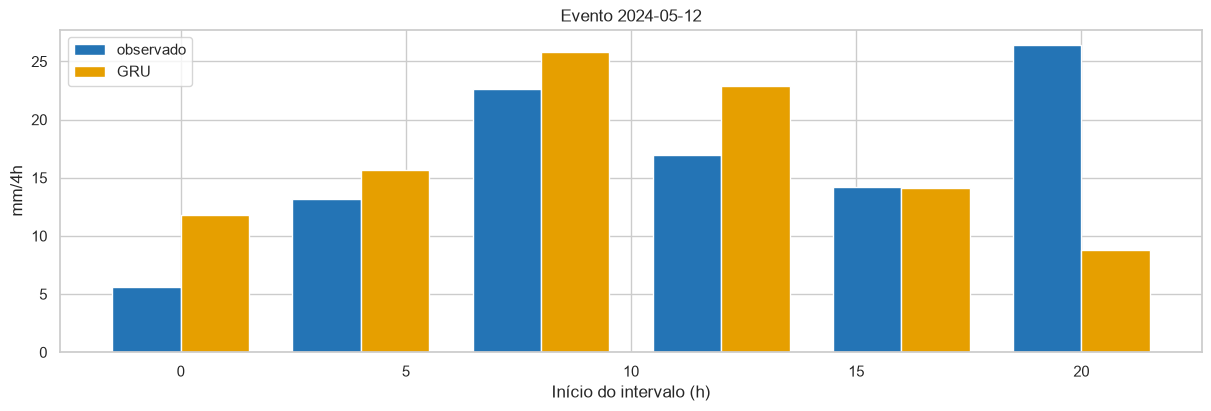

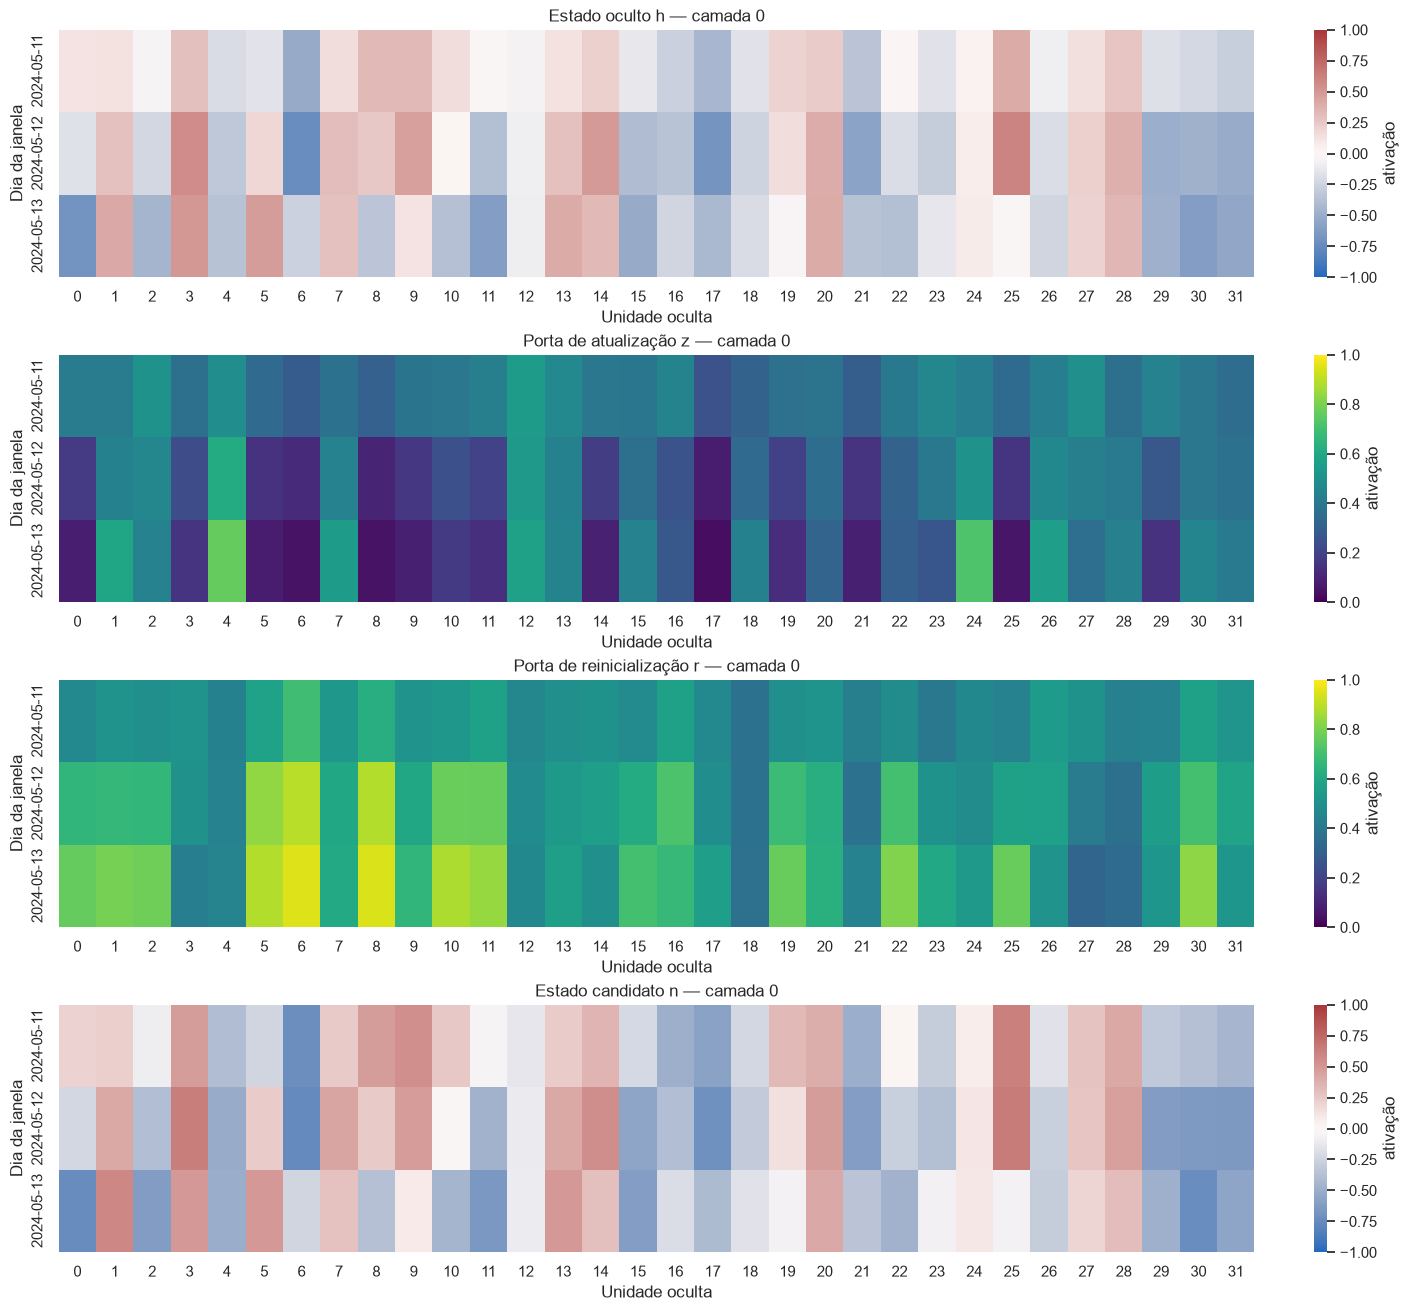

,data,z_media,r_media,n_media,h_media
0,2024-05-11,0.396577,0.502586,-0.003261,-0.003748
1,2024-05-12,0.309719,0.598210,-0.074512,-0.052214
2,2024-05-13,0.302480,0.637887,-0.136343,-0.119267


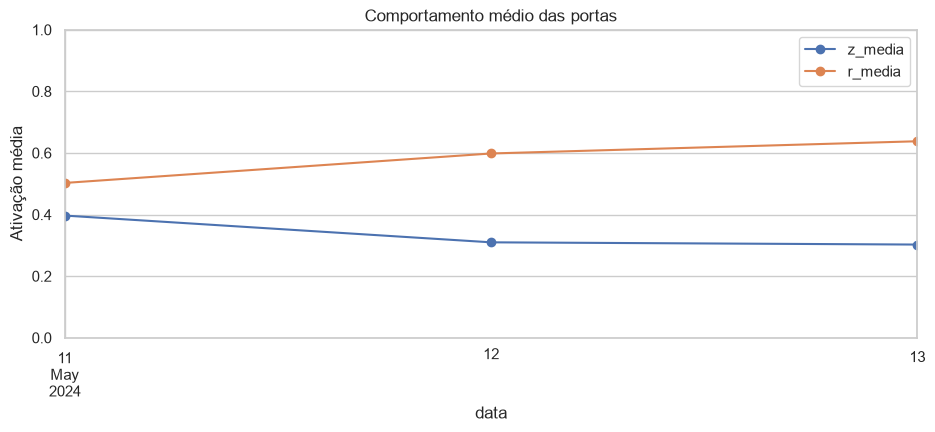

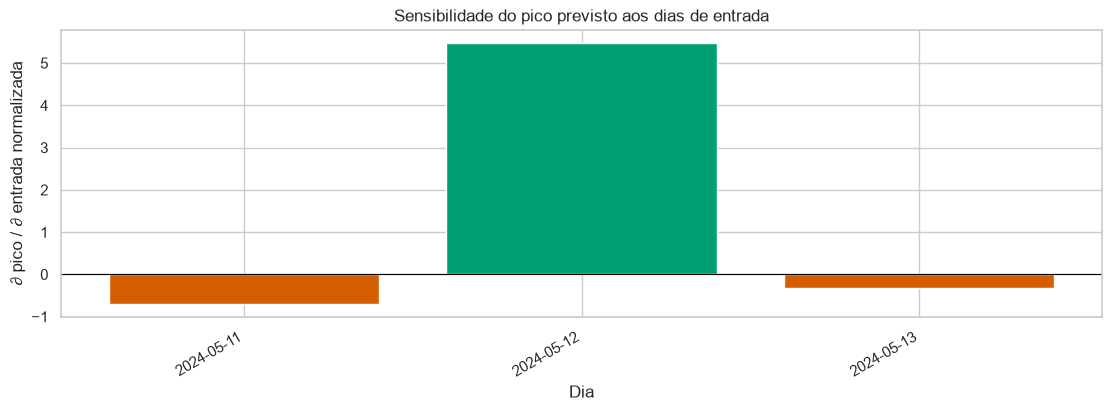

Leitura correta:
- z próximo de 1: a unidade preserva mais do estado anterior.
- z próximo de 0: a unidade substitui mais o estado pelo candidato n.
- r próximo de 0: reduz a contribuição do estado anterior ao calcular n.
- o gradiente mostra sensibilidade local; não prova causalidade meteorológica.


In [13]:
# Descomente para inspecionar o modelo/data definidos no início:
diagnostico = inspecionar_evento(
    caminho_modelo=MODELO_ESCOLHIDO,
    data_evento=DATA_EVENTO,
    camada=CAMADA_PARA_GRAFICO,
)

## Interface para escolher modelo e evento

In [14]:
try:
    import ipywidgets as widgets

    modelos = sorted(PASTA_MODELOS.glob("*.pt"))
    if not modelos:
        print("Nenhum modelo disponível. Treine um modelo no notebook 2.")
    else:
        w_modelo = widgets.Dropdown(
            options=[(p.name, str(p)) for p in modelos],
            description="Modelo:",
            layout=widgets.Layout(width="700px"),
        )
        w_evento = widgets.Dropdown(description="Evento:", layout=widgets.Layout(width="350px"))
        w_camada = widgets.IntSlider(value=0, min=0, max=0, description="Camada:")
        botao = widgets.Button(description="Inspecionar", button_style="primary", icon="search")
        saida = widgets.Output()

        def atualizar_eventos(*_):
            modelo, cfg = carregar_checkpoint(w_modelo.value)
            amostras = construir_amostras_teste(carregar_horario(CAMINHO_DADOS), cfg)
            maiores = sorted(amostras, key=lambda a: a["total"], reverse=True)[:30]
            w_evento.options = [
                (f"{a['data'].date()} — {a['total']:.1f} mm", str(a["data"].date()))
                for a in maiores
            ]
            w_camada.max = cfg["num_layers"] - 1
            w_camada.value = cfg["num_layers"] - 1

        def ao_inspecionar(_):
            with saida:
                clear_output(wait=True)
                inspecionar_evento(w_modelo.value, w_evento.value, w_camada.value)

        w_modelo.observe(atualizar_eventos, names="value")
        botao.on_click(ao_inspecionar)
        atualizar_eventos()
        display(widgets.VBox([w_modelo, widgets.HBox([w_evento, w_camada]), botao, saida]))
except ImportError:
    print("ipywidgets não está instalado. Use a célula anterior.")

## Interpretação científica

As portas não devem ser interpretadas isoladamente como variáveis físicas. Elas são mecanismos matemáticos distribuídos entre várias unidades ocultas. Uma unidade com (z_t\approx1) conserva mais memória, enquanto (z_t\approx0) favorece o estado candidato. A porta (r_t) controla quanto do estado anterior participa da construção do candidato (n_t).

Para o trabalho, use estas visualizações para explicar **como a GRU processa a janela temporal**. Para afirmar importância dos dias, combine o gradiente de sensibilidade com análises em vários eventos, não apenas um exemplo.